In [1]:
# %pip install nbconvert

from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from src.eda import (
    figure,
    resume_univarie,
    profil_par_rayon,
    cramers_v,
    completude_par_groupe,
    incoherences_metier,
    correlations_nutriscore,
    paires_redondantes,
    correlations_par_rayon,
    extremes_restants,
    comparer_deux_groupes,
)

### 0. Données

In [2]:
# Ce nettoyage sera remplacé par celui du TP 9:

CSV_SOURCE = '../data/source/echantillon_france.csv'

RAYON = "pnns_groups_1"
NUTRIMENTS = [
    "energy-kcal_100g", "fat_100g", "saturated-fat_100g", "carbohydrates_100g",
    "sugars_100g", "fiber_100g", "proteins_100g", "salt_100g", "sodium_100g",
    "fruits-vegetables-legumes_100g",
]
NUTRIMENTS_CLES = [
    "energy-kcal_100g", "fat_100g", "saturated-fat_100g", "carbohydrates_100g",
    "sugars_100g", "proteins_100g", "salt_100g",
]

def charger_propre() -> tuple[pd.DataFrame, dict[str, int]]:
    """Échantillon nettoyé a minima + compte rendu des lignes écartées."""
    df = pd.read_csv(CSV_SOURCE, dtype={"code": "string"}, low_memory=False)
    cr = {"lignes_entree": len(df)}
    d = df.drop_duplicates(subset="code", keep="first")
    cr["doublons_codes"] = len(df) - len(d)
    ok = pd.Series(True, index=d.index)
    for c in NUTRIMENTS:
        if c != "energy-kcal_100g":
            ok &= d[c].isna() | d[c].between(0, 100)
    cr["hors_bornes"] = int((~ok).sum())
    d = d[ok]
    ok_e = d["energy-kcal_100g"].isna() | d["energy-kcal_100g"].between(0, 900)
    cr["energie_implausible"] = int((~ok_e).sum())
    d = d[ok_e]
    connu = d[RAYON].notna() & (d[RAYON] != "unknown")
    cr["rayon_inconnu"] = int((~connu).sum())
    d = d[connu].reset_index(drop=True)
    cr["lignes_sortie"] = len(d)
    return d, cr

In [3]:
df, cr = charger_propre()
print(cr)

{'lignes_entree': 8689, 'doublons_codes': 26, 'hors_bornes': 136, 'energie_implausible': 127, 'rayon_inconnu': 1726, 'lignes_sortie': 6674}


### 1. Distributions des nutriments clés par rayon

#### question :
Comment se distribuent les nutriments critiques (sucres, sel, énergie) à l'échelle globale et comment leur concentration varie-t-elle entre les différents rayons alimentaires ?

#### méthode :
* **Fonctions Python :** Exécution de `resume_univarie` (statistiques étendues) et `profil_par_rayon` pour lancer un `groupby` par filière.
* **Filtrage par paramètre :** Nettoyage automatique des échantillons trop faibles via l'argument `min_n=30`.
* **Plots et Métriques :** Génération d'histogrammes (repères moyenne/médiane), de boxplots triés et d'un `pd.crosstab` normalisé couplé au calcul du **V de Cramér** pour mesurer la force de l'association entre le rayon et le grade Nutri-Score.  

**Rappel :** V de Cramér = Résume la liaison en un nombre entre 0 et 1


#### résultat :
**Les profils nutritionnels sont asymétriques et se structurent par rayon**, révélant des contrastes entre les classes produits (ex: snacks vs boissons).  
(voir: Statistique descriptive des 3 nutriments clés)

#### trois lignes :
* **Biais de la moyenne arithmétique** : Les indicateurs d'asymétrie positive des sucres (1.89) et du sel (11.13) prouvent l'écrasement des distributions vers zéro; la moyenne y est supérieure à la médiane, ce qui la disqualifie comme mesure.
* **Sensibilité extrême de l'aplatissement** : L'aplatissement du sel (240.78) est provoqué par une traîne d'observations (max 77.5g), ce qui démontre la nécessité d'utiliser la déviation absolue médiane (MAD) comme mesure de dispersion robuste.
* **Pouvoir de structuration du rayon** : Le coefficient V de Cramér de 0.34 atteste d'une association forte entre le type de rayon et la note finale Nutri-Score.  

**Rappel :** MAD = (Median Absolute Deviation) ; dispersion robuste ; l'équivalent médian de l'écart-type

#### décision :
* **Décision 1** : La variable catégorielle `pnns_groups_1` (rayon) sera obligatoirement intégrée comme variable principale dans le modèle prédictif, son fort pouvoir discriminant V = 0.34 empêchant d'agréger les aliments de manière uniforme.
* **Décision 2** : Pour le message d'ouverture nous utiliserons l'argument de la supériorité de la médiane et de la MAD pour justifier l'abandon des métriques classiques (moyenne/écart-type).
* **Décision 3 (Nettoyage et filtrage)** : Les sous-rayons ou rayons marginaux n'atteignant pas le seuil de stabilité de 30 observations (ex: sous-rayon "Offals", n=23 ou rayon "Baby foods") seront systématiquement exclus ou fusionnés dans une catégorie "Autres" pour les phases de modélisation.

Statistique descriptive des 3 nutriments clés


,n,manquants,moyenne,mediane,ecart_type,IQR,MAD,CV,asymetrie,aplatissement,min,max
sugars_100g,5546.0,1128.0,12.938774,3.0,19.789862,15.6000,3.00,1.529501,1.887813,2.938075,0.0,100.0
salt_100g,5418.0,1256.0,1.065075,0.5,2.372993,1.2498,0.49,2.228005,11.129568,240.781448,0.0,77.5
energy-kcal_100g,5599.0,1075.0,275.073776,254.0,192.814297,286.0000,143.00,0.700955,0.709334,0.252448,0.0,900.0


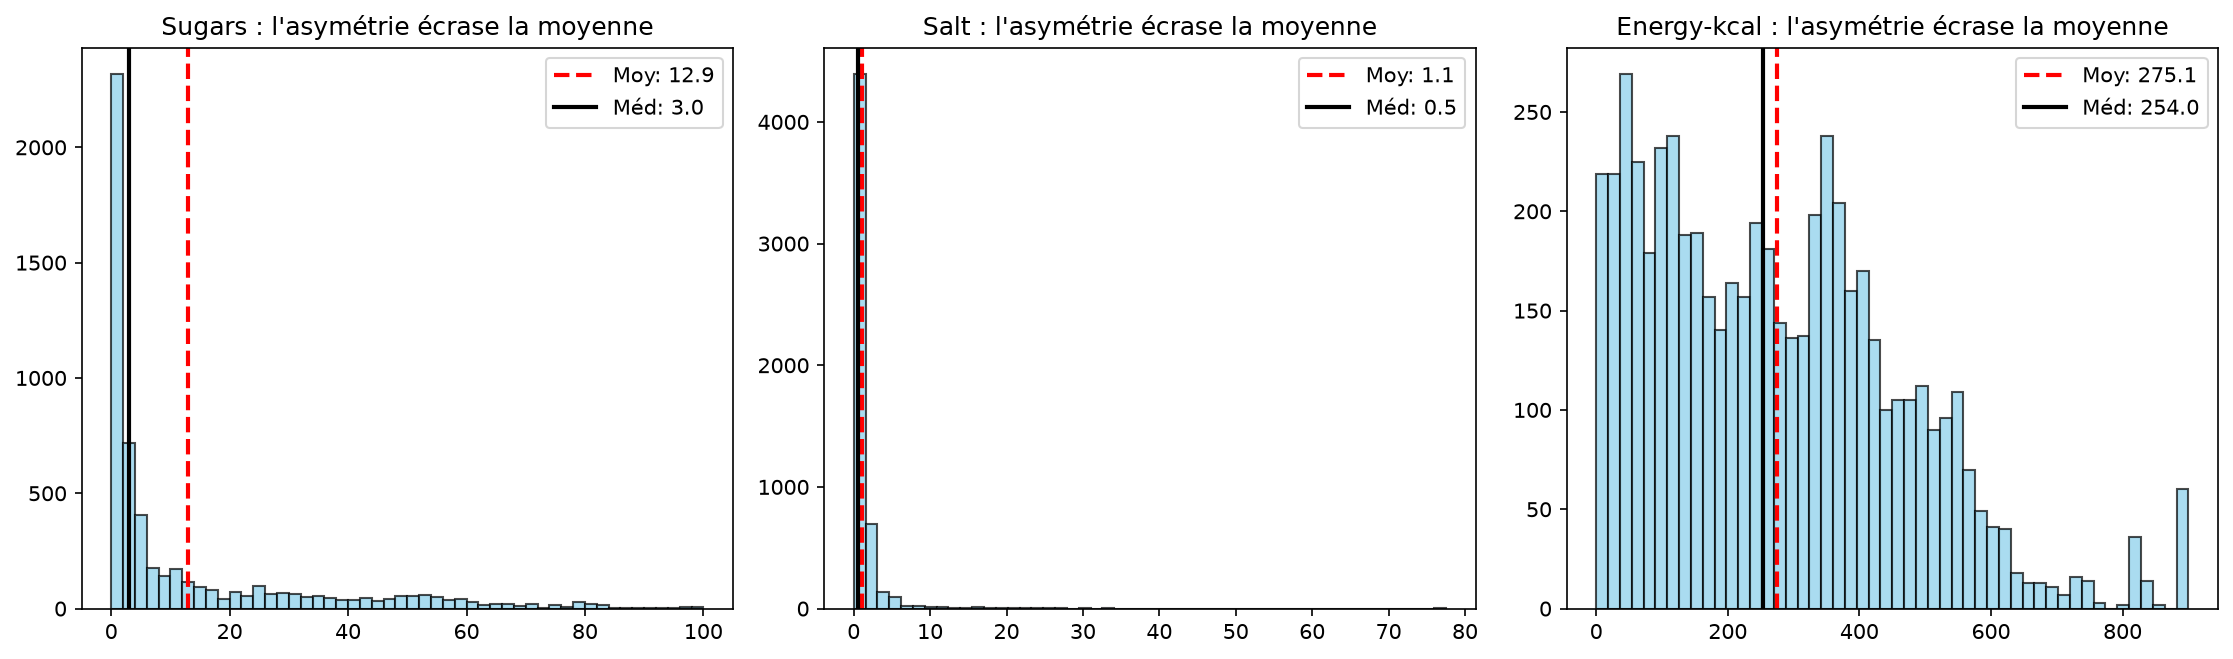

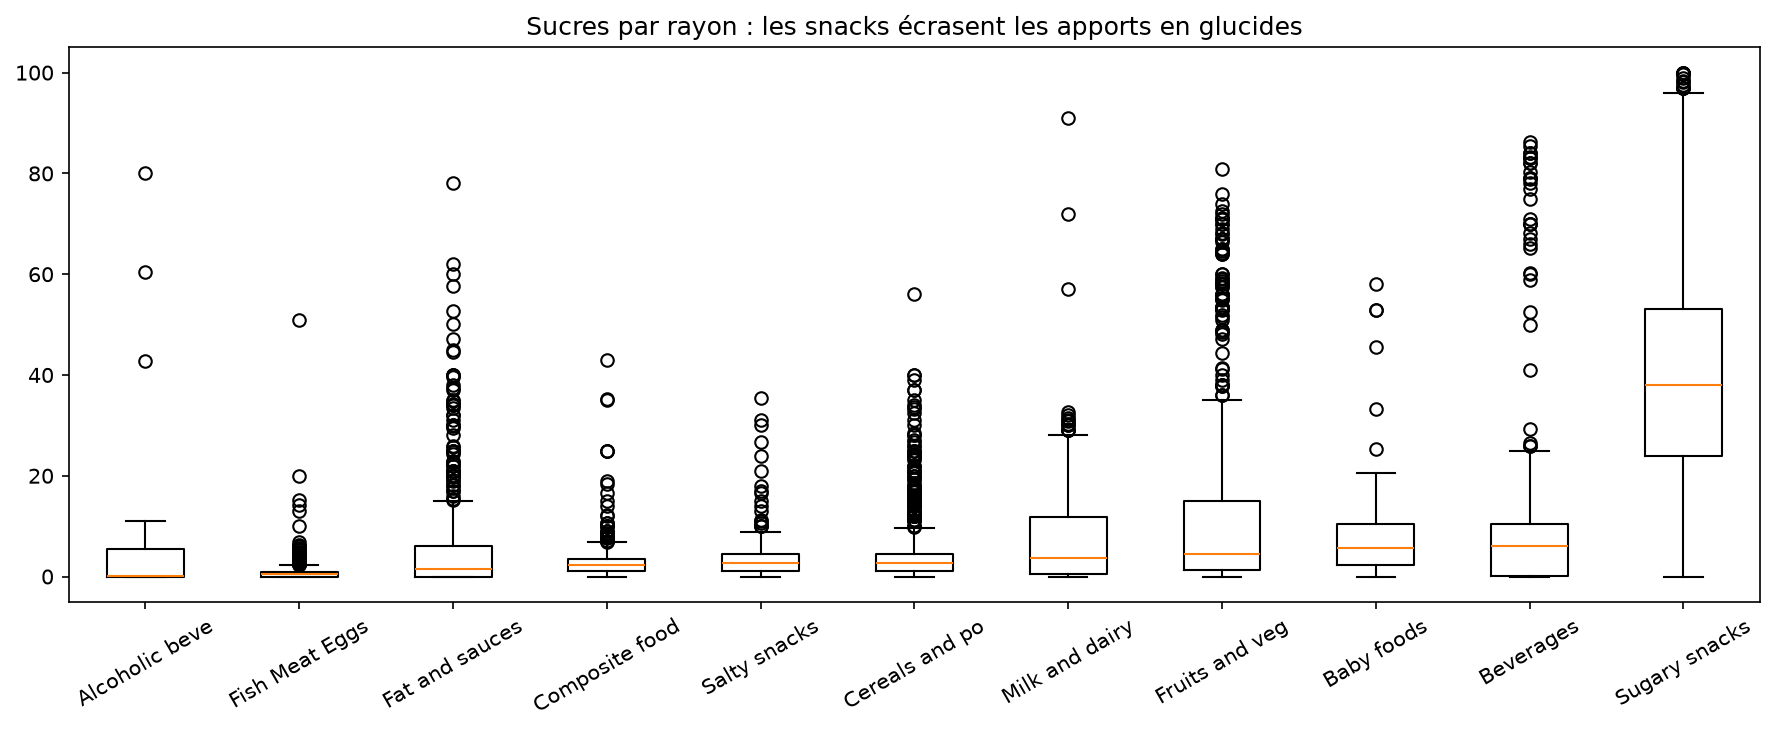

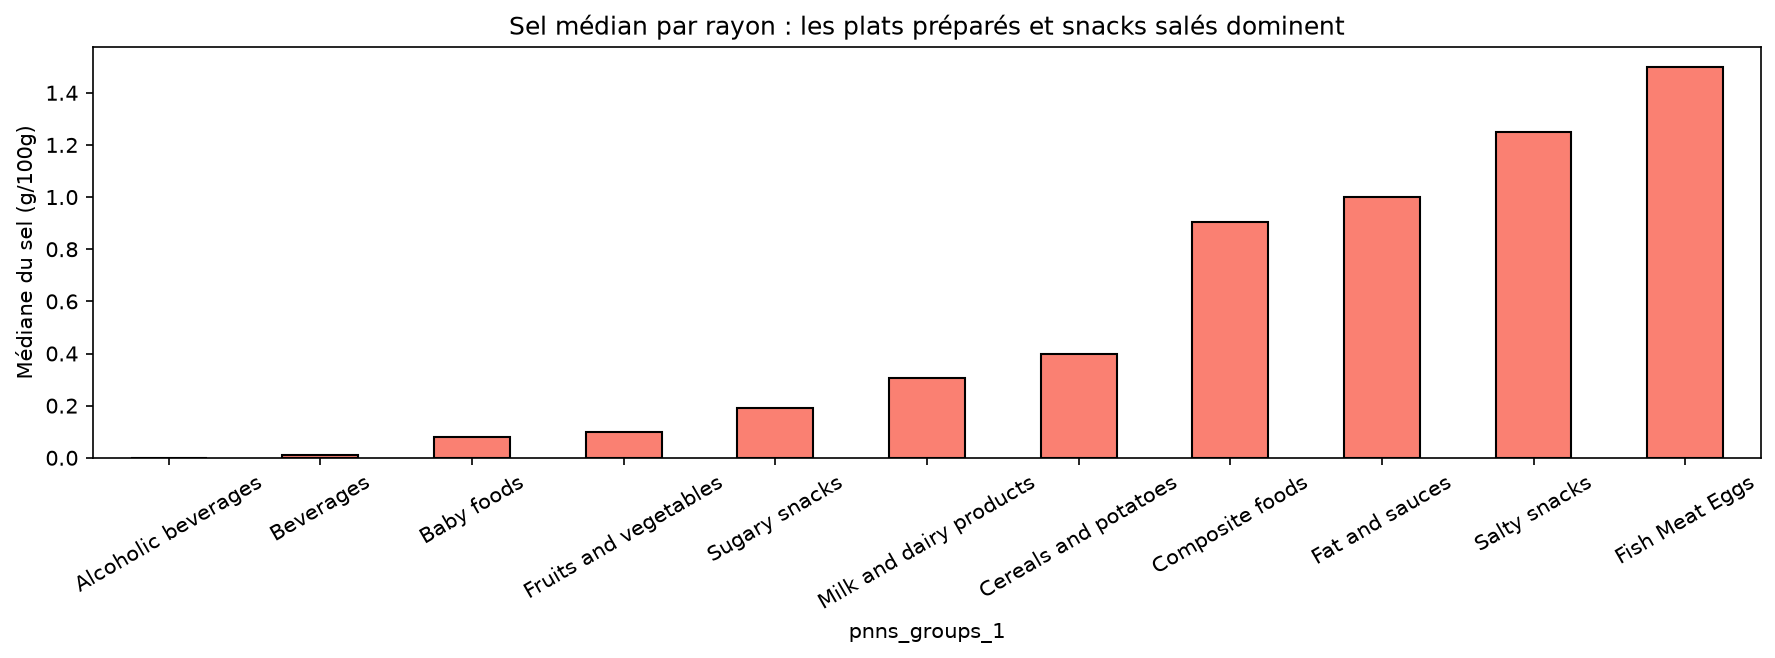

Coefficient V de Cramér (Rayon × Grade) : 0.343


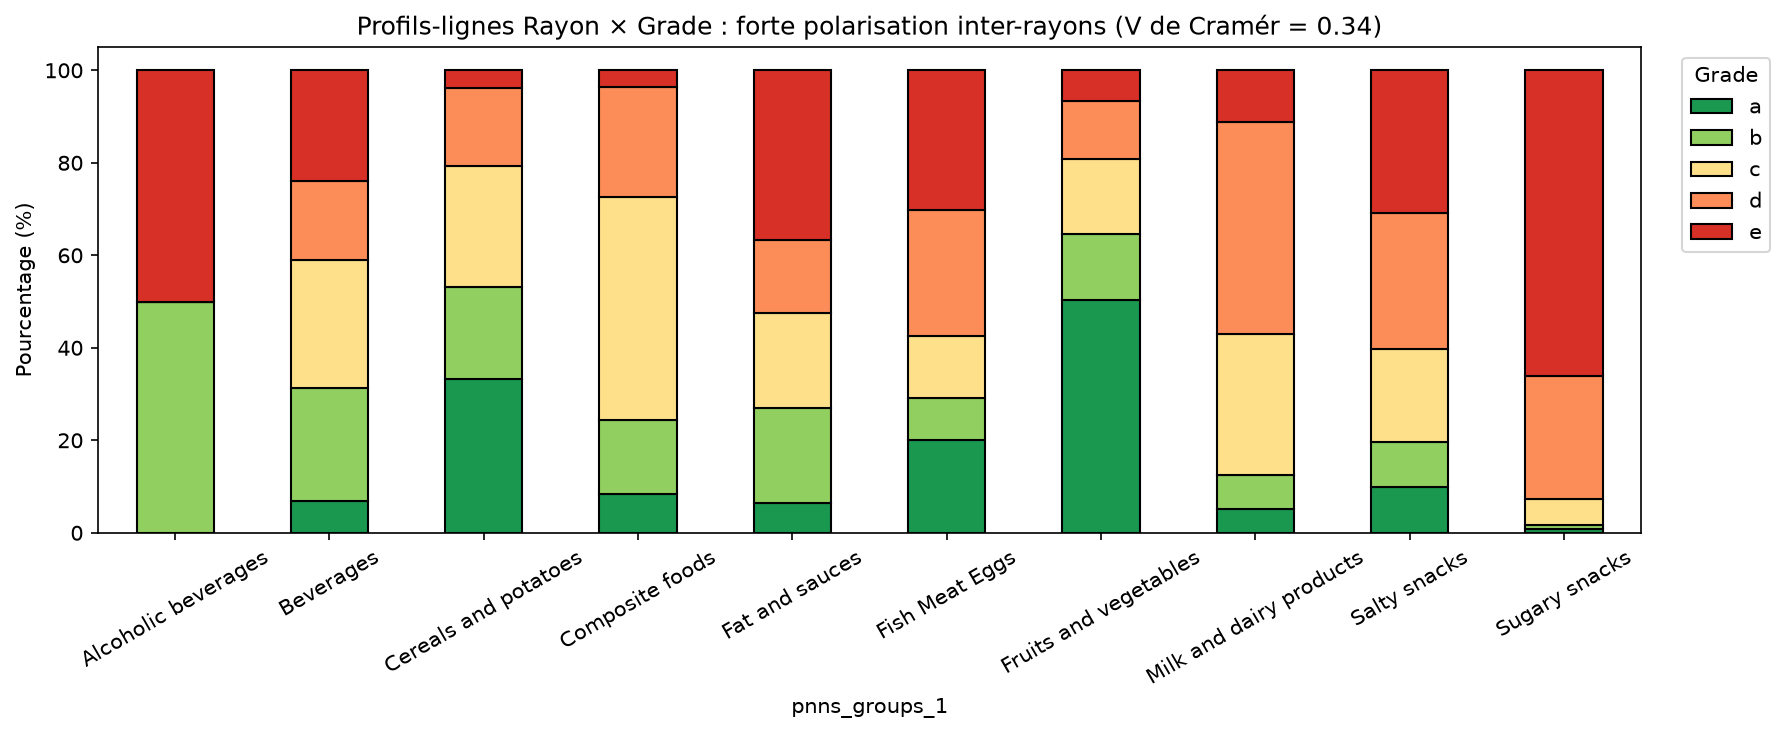

In [4]:
NUTRIMENTS_CIBLE = ["sugars_100g", "salt_100g", "energy-kcal_100g"]

tableau_resume = pd.DataFrame({col: resume_univarie(df[col]) for col in NUTRIMENTS_CIBLE}).T
print("Statistique descriptive des 3 nutriments clés")
display(tableau_resume)

# Histogrammes
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for i, col in enumerate(NUTRIMENTS_CIBLE):
    x = df[col].dropna()
    axes[i].hist(x, bins=50, color="skyblue", edgecolor="black", alpha=0.7)
    axes[i].axvline(x.mean(), color="red", linestyle="--", lw=2, label=f"Moy: {x.mean():.1f}")
    axes[i].axvline(x.median(), color="black", linestyle="-", lw=2, label=f"Méd: {x.median():.1f}")
    axes[i].set_title(f"{col.split('_')[0].capitalize()} : l'asymétrie écrase la moyenne")
    axes[i].legend()
fig.tight_layout()
figure(fig, "histogrammes_nutriments")
plt.show()

# Profils par rayon
res_profil, rayons_exclus = profil_par_rayon(df, NUTRIMENTS_CIBLE, min_n=30)

# Tri des rayons par ordre croissant de la médiane des sucres
ordre_rayons = df.groupby(RAYON, observed=True)["sugars_100g"].median().sort_values().index
ordre_rayons = [r for r in ordre_rayons if r not in rayons_exclus.index]

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot([df.loc[df[RAYON] == r, "sugars_100g"].dropna() for r in ordre_rayons],
           tick_labels=[r[:14] for r in ordre_rayons], showfliers=True)
ax.set_title("Sucres par rayon : les snacks écrasent les apports en glucides")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
figure(fig, "boxplots_sucres_triés")
plt.show()

# Barres pour le sel médian par rayon
sel_median = df.groupby(RAYON, observed=True)["salt_100g"].median().sort_values()
sel_median = sel_median[~sel_median.index.isin(rayons_exclus.index)]

fig, ax = plt.subplots(figsize=(12, 4.5))
sel_median.plot(kind="bar", ax=ax, color="salmon", edgecolor="black")
ax.set_title("Sel médian par rayon : les plats préparés et snacks salés dominent")
ax.set_ylabel("Médiane du sel (g/100g)")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
figure(fig, "barres_sel_median")
plt.show()

# Croisement Rayon × Grade et Cramér's V
g_df = df[df["nutriscore_grade"].isin(list("abcde"))]
table_contingence = pd.crosstab(g_df[RAYON], g_df["nutriscore_grade"])
table_pourcentage = pd.crosstab(g_df[RAYON], g_df["nutriscore_grade"], normalize="index") * 100

v_cramer = cramers_v(table_contingence)
print(f"Coefficient V de Cramér (Rayon × Grade) : {v_cramer:.3f}")

fig, ax = plt.subplots(figsize=(12, 5))
table_pourcentage.plot(kind="bar", stacked=True, ax=ax, 
                       color=["#1a9850", "#91cf60", "#fee08b", "#fc8d59", "#d73027"], edgecolor="black")
ax.set_title(f"Profils-lignes Rayon × Grade : forte polarisation inter-rayons (V de Cramér = {v_cramer:.2f})")
ax.set_ylabel("Pourcentage (%)")
ax.tick_params(axis="x", rotation=30)
ax.legend(title="Grade", bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
figure(fig, "barres_empilees_croisement")
plt.show()


### 2. Complétude et qualité par rayon et par marque

#### question :
Dans quels segments de notre jeux de données (rayons ou marques) les données nutritionnelles affichent-elles des lacunes ou des incohérences remettant en cause la fiabilité du calcul du Nutri-Score ?

#### méthode :
Complétude conditionnelle par groupe (`completude_par_groupe`) et application d'un filtre d'exclusion pour les rayons de faible volume (min_n = 20).  
Un dictionnaire de contrôle (`incoherences_metier`) qui isole de manière booléenne les anomalies de l'échantillon (contradictions de bornes, équilibres du sel et de l'énergie).  
Les visualisations restituent les taux de complétude par rayon, par marque et l'alignement de l'énergie sous forme de nuage de points.

#### résultat :
**La fiabilité des données varie considérablement entre les rayons et les marques industrielles, et la présence d'erreurs sur l'énergie (energie_incoherente) nécessite une intervention directe en amont de la modélisation.**

#### trois lignes :
* **Asymétrie critique de la complétude** : Le taux de fiches complètes chute dans le rayon *Alcoholic beverages* et les marques associées, tandis que les *Sugary snacks* affichent une bonne complétude, biaisant ainsi toute tentative d'analyse comparative brute sans redressement.
* **Détection d'anomalies thermodynamiques** : Des produits s'écartent de plus de 150 kcal de leur valeur théorique calculée par l'équation d'Atwater, ce qui met en évidence des erreurs de saisie manuelles massives de la part des contributeurs.
* **Incohérence des sous-produits sodés** : Des produits violent la règle stricte Sel = 2.5 x Sodium, confirmant des mélanges d'unités ou des déclarations erronées sur l'étiquetage.

#### décision :
* **Zone de prudence maximale** : Exclure le rayon des boissons alcoolisées et les marques de distributeurs à faible effectif (n < 20) de l'apprentissage du modèle de classification en raison de leur taux de complétude bas.
* **Règles pour le nettoyage** : Intégrer les filtres d'incohérences de l'énergie (écarts > 150 kcal et énergie nulle) directement au sein du script de nettoyage pour éliminer ces fiches aberrantes avant toute modélisation.


--- Complétude par Rayon ---


,n,taux_energy-kcal_100g,taux_fat_100g,taux_saturated-fat_100g,taux_carbohydrates_100g,taux_sugars_100g,taux_proteins_100g,taux_salt_100g,taux_fiches_completes,taux_presence_score
pnns_groups_1,,,,,,,,,,
Alcoholic beverages,206,22.3,17.5,23.3,17.0,20.9,17.0,20.4,14.1,1.0
Baby foods,50,100.0,98.0,100.0,98.0,100.0,100.0,94.0,92.0,0.0
Beverages,547,85.6,84.5,81.5,85.4,82.6,84.8,80.8,76.1,68.9
Cereals and potatoes,678,90.3,89.8,88.9,90.0,89.4,90.3,86.1,85.0,84.2
Composite foods,502,91.0,90.6,91.0,90.6,91.0,91.0,90.4,90.0,92.4
Fat and sauces,496,89.5,89.3,89.1,89.3,89.1,89.3,88.3,86.5,82.1
Fish Meat Eggs,1175,81.1,81.1,80.3,80.8,80.0,81.1,80.1,78.6,79.0
Fruits and vegetables,482,77.8,77.6,76.6,77.8,77.4,77.8,72.4,71.0,71.4
Milk and dairy products,775,86.8,86.6,86.1,86.6,85.9,86.6,84.3,83.4,81.9



--- Complétude par Marque (Top 10 trié par effectif) ---


,n,taux_energy-kcal_100g,taux_fat_100g,taux_saturated-fat_100g,taux_carbohydrates_100g,taux_sugars_100g,taux_proteins_100g,taux_salt_100g,taux_fiches_completes,taux_presence_score
brands,,,,,,,,,,
Carrefour,141,63.8,62.4,62.4,63.1,61.7,63.1,63.8,60.3,76.6
Auchan,126,66.7,65.9,66.7,65.9,66.7,66.7,65.9,65.1,87.3
U,109,88.1,89.0,89.0,89.0,89.0,88.1,88.1,87.2,82.6
Leader Price,57,94.7,94.7,94.7,94.7,94.7,94.7,91.2,91.2,82.5
Casino,47,95.7,95.7,95.7,95.7,95.7,95.7,95.7,95.7,95.7
Monoprix,38,89.5,89.5,86.8,89.5,89.5,89.5,86.8,84.2,78.9
Picard,36,100.0,100.0,100.0,100.0,100.0,100.0,97.2,97.2,97.2
Le Gaulois,34,97.1,97.1,97.1,97.1,97.1,97.1,97.1,97.1,97.1
Thiriet,30,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0



--- Synthèse des incohérences métier détectées ---
sucres_gt_glucides                100
satures_gt_lipides                 96
sel_incoherent_sodium             102
energie_incoherente                89
energie_nulle_macros_presentes      9


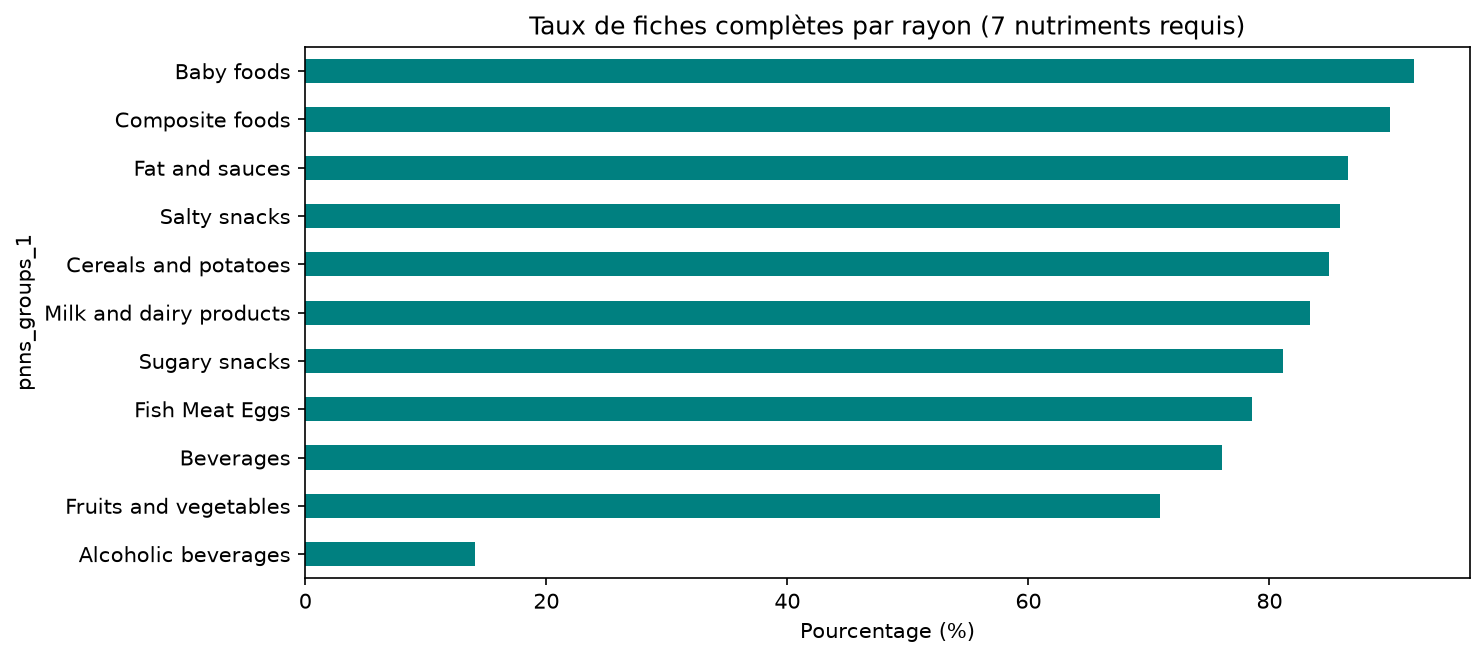

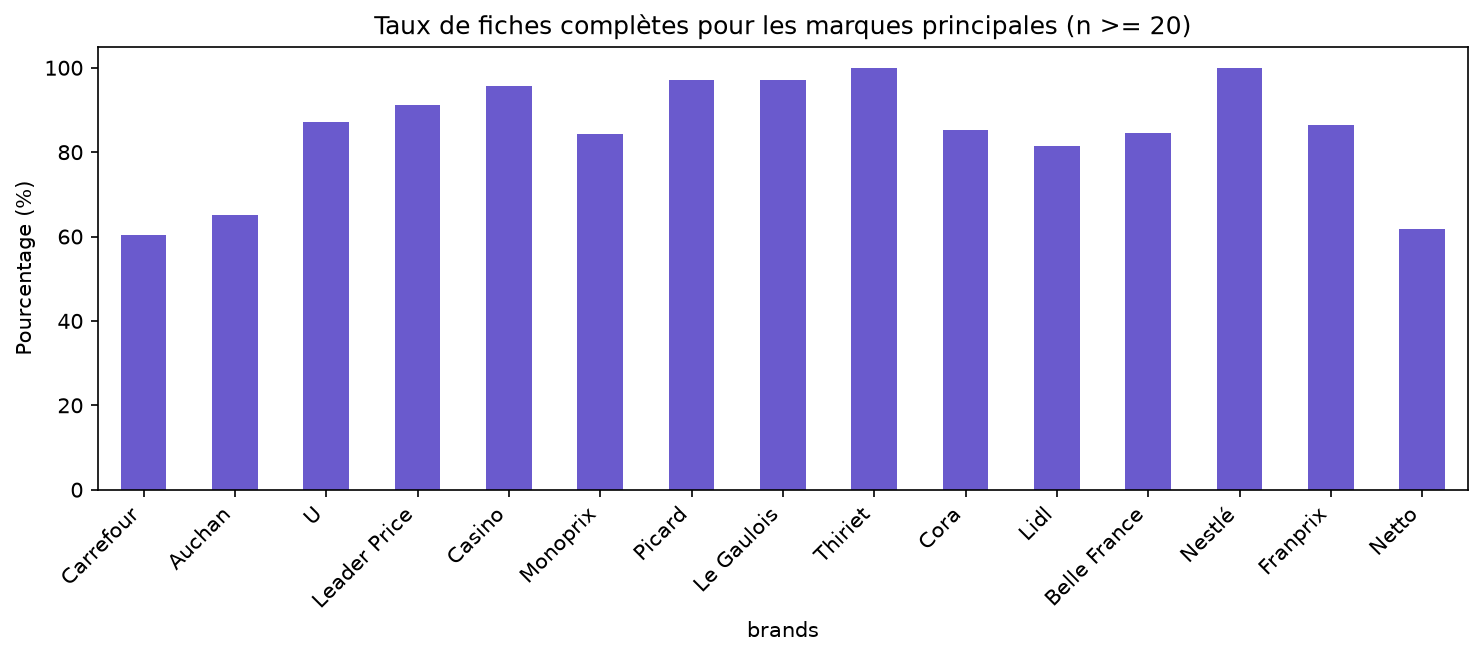

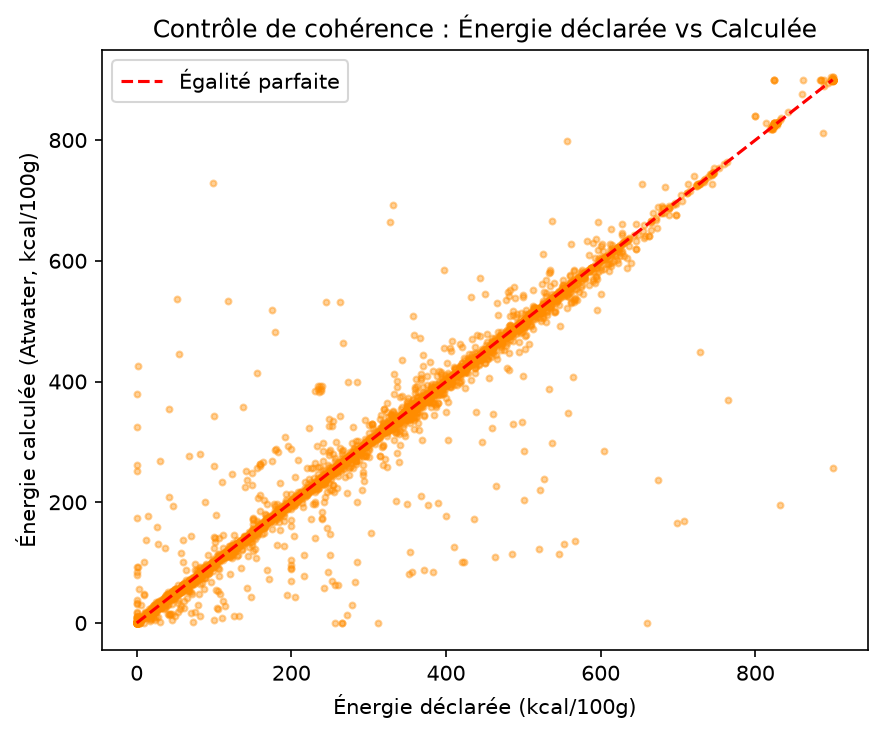

In [5]:
print("--- Complétude par Rayon ---")
completude_rayon = completude_par_groupe(df, groupe=RAYON, colonnes=NUTRIMENTS_CLES, min_n=1)
display(completude_rayon.round(1))

print("\n--- Complétude par Marque (Top 10 trié par effectif) ---")
completude_marque = completude_par_groupe(df, groupe="brands", colonnes=NUTRIMENTS_CLES, min_n=20)
display(completude_marque.sort_values(by="n", ascending=False).head(10).round(1))

print("\n--- Synthèse des incohérences métier détectées ---")
flags_incoherences = incoherences_metier(df)
print(flags_incoherences.sum().to_string())

# Figure 1 : Complétude par Rayon (Taux de fiches complètes)
fig, ax = plt.subplots(figsize=(10, 4.5))
completude_rayon["taux_fiches_completes"].sort_values().plot(kind="barh", ax=ax, color="teal")
ax.set_title("Taux de fiches complètes par rayon (7 nutriments requis)")
ax.set_xlabel("Pourcentage (%)")
fig.tight_layout()
figure(fig, "completude_rayon")
plt.show()

# Figure 2 : Complétude par Marque (Taux de fiches complètes - Top 15 marques par taille)
fig, ax = plt.subplots(figsize=(10, 4.5))
completude_marque.sort_values(by="n", ascending=False).head(15)["taux_fiches_completes"].plot(kind="bar", ax=ax, color="slateblue")
ax.set_title("Taux de fiches complètes pour les marques principales (n >= 20)")
ax.set_ylabel("Pourcentage (%)")
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
figure(fig, "completude_marque")
plt.show()

# Figure 3 : Nuage de points Énergie déclarée × Énergie calculée
fibres_nettoyees = df['fiber_100g'].fillna(0)
energie_theorique = 9 * df['fat_100g'] + 4 * df['carbohydrates_100g'] + 4 * df['proteins_100g'] + 2 * fibres_nettoyees

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(df['energy-kcal_100g'], energie_theorique, alpha=0.4, s=8, c="darkorange")
ax.plot([0, 900], [0, 900], color="red", linestyle="--", label="Égalité parfaite")
ax.set_title("Contrôle de cohérence : Énergie déclarée vs Calculée")
ax.set_xlabel("Énergie déclarée (kcal/100g)")
ax.set_ylabel("Énergie calculée (Atwater, kcal/100g)")
ax.legend()
fig.tight_layout()
figure(fig, "coherence_energie")
plt.show()

### 3. Corrélations nutriments / Nutri-Score

#### question :
Quels sont les nutriments qui guident le calcul du Nutri-Score, comment les redondances colinéaires perturbent-elles la lecture globale, et dans quelle mesure la stratification par rayon révèle-t-elle des inversions de tendance (paradoxe de Simpson) ?  

**Rappel :** paradoxe de Simpson = une tendance observée globalement s'inverse quand on l'observe séparément dans chaque sous-groupe

#### méthode :
Pearson et Spearman via la fonction `correlations_nutriscore`. L'analyse isole les couples redondants avec la fonction `paires_redondantes`.  
Stratification par rayon (`correlations_par_rayon`) et par sous-rayon métier.  
Une Analyse ACP.  

**Rappel :**  
  ACP = transforme des variables numériques corrélées en composantes principales  
  Pearson = Mesure une relation linéaire ; comme la moyenne, sensible aux extrêmes  
  Spearman = Mesure une relation monotone, pas forcément en ligne droite ; robuste aux extrêmes et invariant à toute transformation croissante


#### résultat :
**Les acides gras saturés et l'énergie dictent la trajectoire globale du score, mais l'analyse univariée globale masque un paradoxe de Simpson majeur sur les produits laitiers où le rôle du sucre s'inverse.**

#### trois lignes :
* **Détection et résolution de colinéarité** : Le couple `salt_100g` / `sodium_100g` affiche une corrélation de rang quasi parfaite (0.99), matérialisant un doublon d'information (Sel = 2.5 x Sodium).
* **Paradoxe de Simpson sur le sucre** : Le sucre est corrélé positivement au score (0.39). Pourtant, dans le rayon *Milk and dairy products*, la corrélation s'inverse négativement (-0.30). Les fromages sont mal notés (médiane score = 14) mais ne contiennent aucun sucre, tandis que les yaourts et desserts lactés sont plus sucrés mais mieux notés que les fromages en raison de leur faible teneur en acides gras.
* **Confirmation par l'ACP** : Le premier axe factoriel PC1 (34.7 % de variance expliquée) s'aligne sur le gradient de sévérité du Nutri-Score (les notes évoluant de A à E), validant le fait que l'ACP capture la structure même de la formule de calcul.

#### décision :
* **Décision 1 (Features retenues)** : Pour l'apprentissage du modèle prédictif, la feature `sodium_100g` est **supprimée** pour éliminer la colinéarité parfaite avec `salt_100g`. Nous conservons la paire `fat_100g` / `saturated-fat_100g` car certains modèles d'arbres tolèrent la colinéarité, mais l'indicateur d'acides gras saturés sera privilégié si une régression linéaire est testée.
* **Décision 2 (Stratification indispensable)** : Le modèle linéaire global est incapable de capter les comportements opposés des macronutriments (comme le sucre dans les laitages). Le modèle devra intégrer des segmentations par rayon (`pnns_groups_1`) pour s'ajuster aux règles de calcul.


--- Corrélations globales avec le score de Nutri-Score ---


,n,pearson,spearman
variable,,,
saturated-fat_100g,5006,0.472,0.538
energy-kcal_100g,5011,0.442,0.525
fat_100g,5011,0.301,0.465
sugars_100g,5008,0.476,0.392
salt_100g,5012,0.309,0.387
sodium_100g,5012,0.301,0.381
carbohydrates_100g,5008,0.304,0.268
fruits-vegetables-legumes_100g,2993,-0.333,-0.240
fiber_100g,2697,-0.085,-0.079


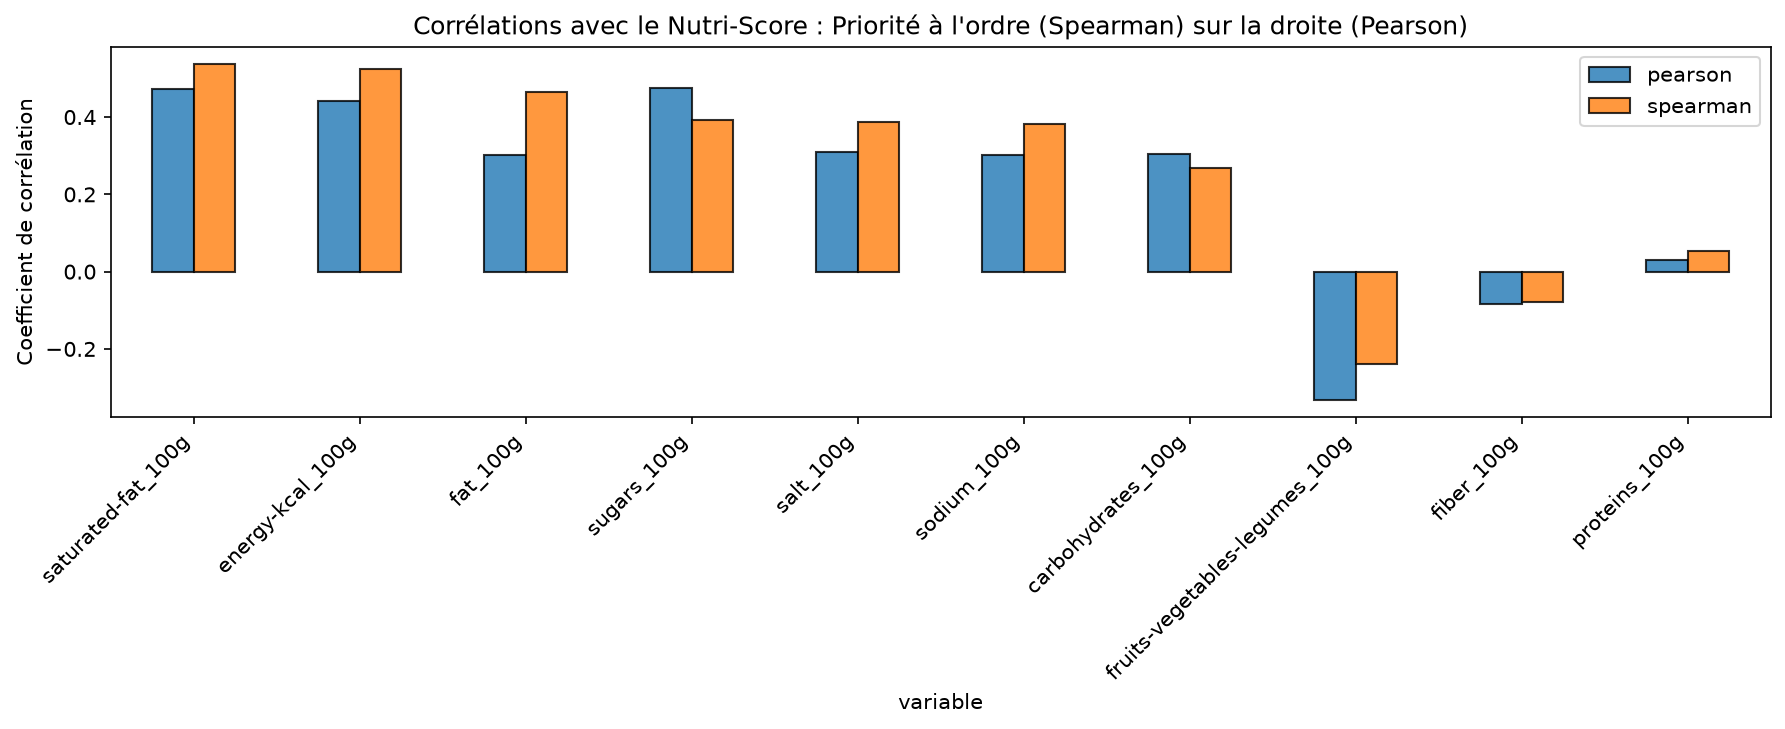


--- Paires de nutriments redondantes détectées (|rho| >= 0.8) ---


,Var1,Var2,Correlation
0,fat_100g,saturated-fat_100g,0.892
1,salt_100g,sodium_100g,0.990


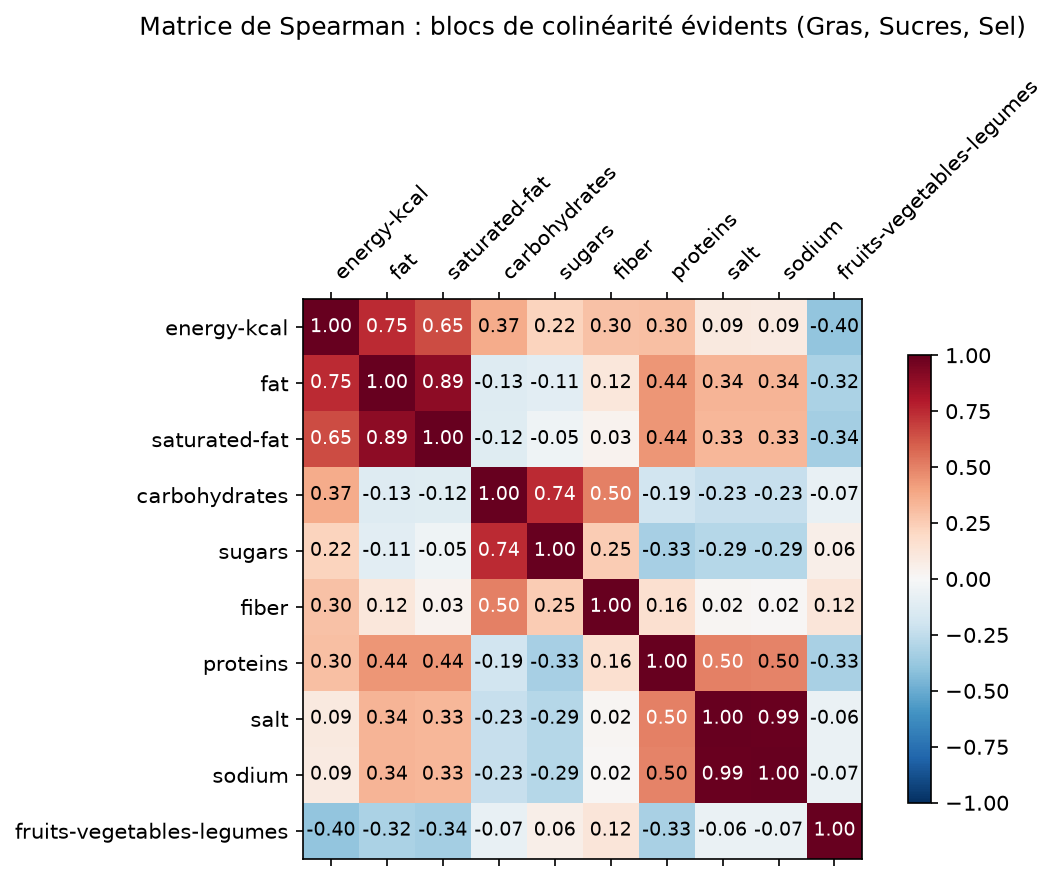


--- Analyse stratifiée par Rayon pour les Sucres ---


,n,pearson,spearman
rayon,,,
Beverages,359,0.624,0.795
Cereals and potatoes,553,0.417,0.312
Composite foods,443,0.299,0.210
Fat and sauces,402,0.363,0.432
Fish Meat Eggs,908,0.127,0.333
Fruits and vegetables,329,0.744,0.532
Milk and dairy products,614,0.028,-0.297
Salty snacks,320,-0.105,-0.336
Sugary snacks,1078,0.330,0.301



--- Analyse stratifiée par Rayon pour le Sel ---


,n,pearson,spearman
rayon,,,
Beverages,360,0.220,0.255
Cereals and potatoes,553,0.500,0.683
Composite foods,443,0.415,0.645
Fat and sauces,402,0.519,0.765
Fish Meat Eggs,909,0.593,0.829
Fruits and vegetables,329,0.320,0.225
Milk and dairy products,616,0.549,0.695
Salty snacks,320,0.589,0.671
Sugary snacks,1078,0.197,0.281



--- Corrélations au sein du sous-rayon Milk and dairy products ---


,n,spearman_sucres
sub_rayon,,
Cheese,304,-0.083
Dairy desserts,88,0.581
Ice cream,73,0.484
Milk and yogurt,149,0.384



Variance expliquée par le plan factoriel (PC1 + PC2) : 50.3%


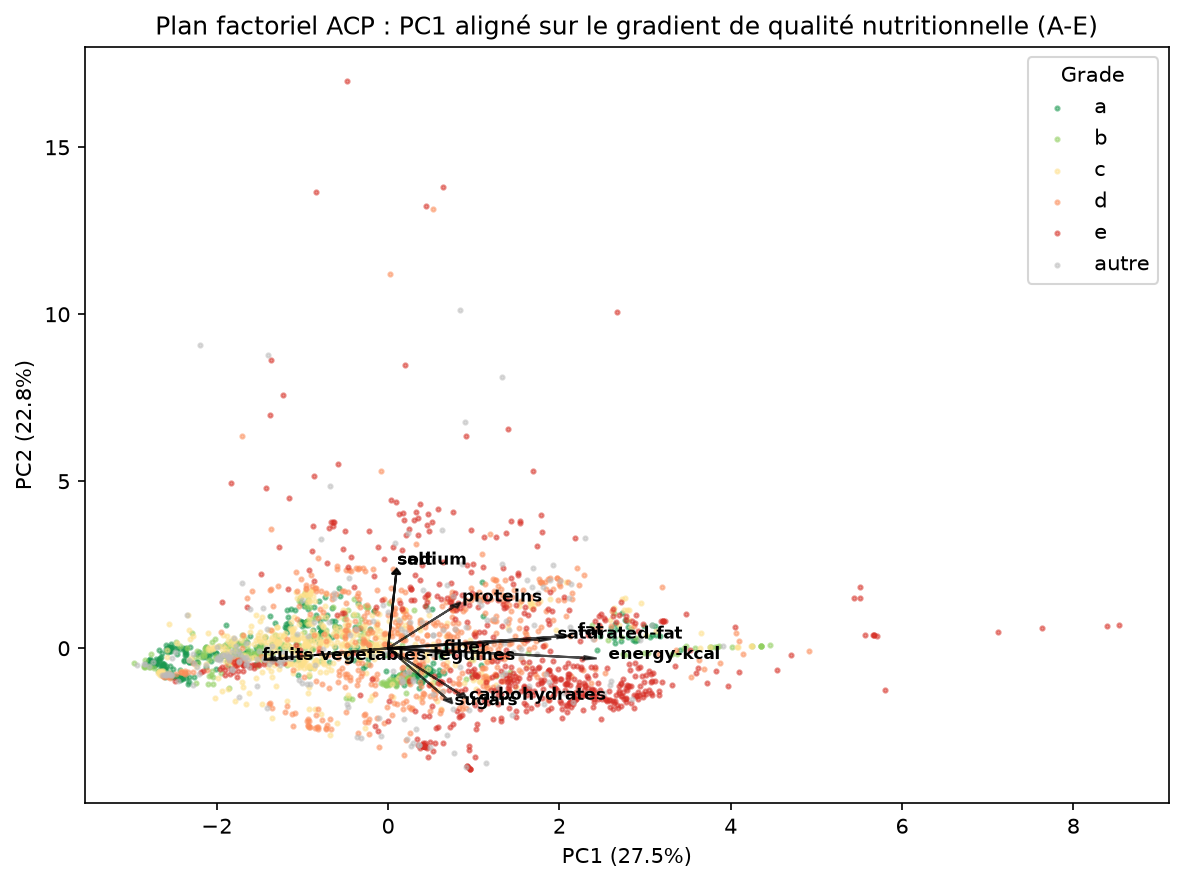

In [6]:
cible_score = "nutriscore_score"

# Corrélations avec le Nutri-Score
print("--- Corrélations globales avec le score de Nutri-Score ---")
table_corr_globale = correlations_nutriscore(df, NUTRIMENTS, cible_score)
display(table_corr_globale.round(3))

# Figure 1 : Barres doubles Pearson vs Spearman
fig, ax = plt.subplots(figsize=(12, 5))
table_corr_globale[["pearson", "spearman"]].plot(kind="bar", ax=ax, edgecolor="black", alpha=0.8)
ax.set_title("Corrélations avec le Nutri-Score : Priorité à l'ordre (Spearman) sur la droite (Pearson)")
ax.set_ylabel("Coefficient de corrélation")
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
figure(fig, "double_barres_correlations")
plt.show()

# Matrice de corrélation de Spearman & Paires redondantes
matrice_spearman = df[NUTRIMENTS].corr(method="spearman")
df_redondances = paires_redondantes(matrice_spearman, seuil=0.8)
print("\n--- Paires de nutriments redondantes détectées (|rho| >= 0.8) ---")
display(df_redondances.round(3))

# Figure 2 : Heatmap exploratoire des corrélations avec valeurs numériques
fig, ax = plt.subplots(figsize=(8, 6))
cax = ax.matshow(matrice_spearman, cmap="RdBu_r", vmin=-1, vmax=1)
fig.colorbar(cax, ax=ax, shrink=0.8)
ax.set_xticks(range(len(NUTRIMENTS)))
ax.set_yticks(range(len(NUTRIMENTS)))
ax.set_xticklabels([c.replace("_100g", "") for c in NUTRIMENTS], rotation=45, ha="left")
ax.set_yticklabels([c.replace("_100g", "") for c in NUTRIMENTS])
for i in range(len(NUTRIMENTS)):
    for j in range(len(NUTRIMENTS)):
        valeur = matrice_spearman.iloc[i, j]
        couleur_texte = "white" if abs(valeur) > 0.5 else "black"
        ax.text(j, i, f"{valeur:.2f}", ha="center", va="center", color=couleur_texte, fontsize=9)
ax.set_title("Matrice de Spearman : blocs de colinéarité évidents (Gras, Sucres, Sel)", pad=20)
fig.tight_layout()
figure(fig, "heatmap_spearman")
plt.show()

# Corrélations par rayon pour le sucre et le sel
print("\n--- Analyse stratifiée par Rayon pour les Sucres ---")
corr_sucre_rayon = correlations_par_rayon(df, "sugars_100g", cible_score)
display(corr_sucre_rayon.round(3))

print("\n--- Analyse stratifiée par Rayon pour le Sel ---")
corr_sel_rayon = correlations_par_rayon(df, "salt_100g", cible_score)
display(corr_sel_rayon.round(3))

# Focus Produits Laitiers par sous-rayon (pnns_groups_2)
print("\n--- Corrélations au sein du sous-rayon Milk and dairy products ---")
df_laitiers = df[df[RAYON] == "Milk and dairy products"]
lignes_laitiers = []
for s_rayon, sous_df in df_laitiers.groupby("pnns_groups_2", observed=True):
    paire_valide = sous_df[["sugars_100g", cible_score]].dropna()
    if len(paire_valide) >= 30:
        lignes_laitiers.append({
            "sub_rayon": s_rayon,
            "n": len(paire_valide),
            "spearman_sucres": paire_valide["sugars_100g"].corr(paire_valide[cible_score], method="spearman")
        })
display(pd.DataFrame(lignes_laitiers).set_index("sub_rayon").round(3))

# ACP SUR NUTRIMENTS STANDARDISÉS
df_acp = df.dropna(subset=NUTRIMENTS)
Z = StandardScaler().fit_transform(df_acp[NUTRIMENTS])
pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(Z)

print(f"\nVariance expliquée par le plan factoriel (PC1 + PC2) : {pca.explained_variance_ratio_.sum()*100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 6))
couleurs_grade = {"a": "#1a9850", "b": "#91cf60", "c": "#fee08b", "d": "#fc8d59", "e": "#d73027"}
grade = df_acp["nutriscore_grade"].where(df_acp["nutriscore_grade"].isin(list("abcde")), "autre")

for g, col in list(couleurs_grade.items()) + [("autre", "#bbbbbb")]:
    m = (grade == g).to_numpy()
    ax.scatter(P[m, 0], P[m, 1], s=4, alpha=0.5, c=col, label=g)

# Tracer le cercle des corrélations simplifié (charges) par-dessus
for i, v in enumerate(NUTRIMENTS):
    ax.arrow(0, 0, pca.components_[0, i]*4, pca.components_[1, i]*4, color="black", head_width=0.1, alpha=0.7)
    ax.text(pca.components_[0, i]*4.5, pca.components_[1, i]*4.5, v.replace("_100g", ""), fontsize=8, weight="bold")

ax.set_title("Plan factoriel ACP : PC1 aligné sur le gradient de qualité nutritionnelle (A-E)")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.legend(title="Grade")
fig.tight_layout()
figure(fig, "acp_factoriel_grades")
plt.show()


### 4. Valeurs extrêmes restantes

#### question :
Quelles sont les valeurs extrêmes qui subsistent dans nos données par rapport à la distribution de leur propre rayon, et comment séparer les véritables caractéristiques produits (valeurs vraies) des anomalies de saisie (valeurs résiduelles) ?

#### méthode :
Développement d'un estimateur robuste basé sur `zscore_robuste`.  
Application par rayon via la fonction `extremes_restants`.  
Inspection manuelle des 15 cas les plus intenses.  

**Rappel :** zscore_robuste = indicateur qui sert à mesurer un outlier dans un jeu de données

#### résultat :
L'analyse montre une cohabitation claire entre des extrêmes biologiques ou industriels (produits secs, concentrés, poudres) et des erreurs de saisie d'unités (notamment des confusions entre grammes et milligrammes).

| Rang | Produit | Rayon | Variable | Valeur | Type d'extrême | Justification / Diagnostic |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| 1 | Eau minérale naturelle gazeuse fines bulles | Beverages | `salt_100g` | 77.5 g | **Résiduelle** | Erreur de saisie évidente, une eau minérale ne peut pas être saturée de sel à ce niveau (probable confusion mg/g). |
| 2 | with Aloe Vera | Beverages | `salt_100g` | 30.0 g | **Résiduelle** | Boisson rafraîchissante à l'aloe vera aberrante, taux de sel physiologiquement impossible. |
| 3 | ifruit orange mangue au lait | Beverages | `salt_100g` | 7.84 g | **Résiduelle** | Boisson fruitée et lactée contenant du sel à un niveau irréaliste (supérieur à de l'eau de mer). |
| 4 | Noix De Coco Râpée | Fruits and vegetables | `saturated-fat_100g` | 57.2 g | **Vraie** | La noix de coco séchée/déshydratée est naturellement composée à plus de 50% d'acides gras saturés. |
| 5 | Nick Maple-sirup | Alcoholic beverages | `sugars_100g` | 80.0 g | **Vraie** | Composition exacte pour un sirop d'érable (pur sucre), mais produit victime d'une mauvaise catégorisation PNNS. |
| 6 | Noix de coco râpée | Fruits and vegetables | `saturated-fat_100g` | 55.0 g | **Vraie** | Caractéristique de la noix de coco déshydratée (similaire au rang 4). |
| 7 | Giffard crème de cassis d'Anjou 16° | Alcoholic beverages | `sugars_100g` | 60.364 g | **Vraie** | Les crèmes de fruits et liqueurs alcoolisées sont massivement enrichies en sucre par définition réglementaire. |
| 8 | Lean Pro8 Lean Protein Blend - Chocolate | Beverages | `proteins_100g` | 50.0 g | **Vraie** | Poudre de protéines concentrée, valeur normale pour ce type de préparation (classée ici car vendue comme mix de boisson). |
| 9 | Noix de coco | Fruits and vegetables | `saturated-fat_100g` | 33.3 g | **Vraie** | Taux normal d'acides gras saturés pour de la pulpe de noix de coco fraîche. |
| 10 | Noix de coco | Fruits and vegetables | `saturated-fat_100g` | 33.3 g | **Vraie** | Identique au rang 9. |
| 11 | Kokosnuss | Fruits and vegetables | `saturated-fat_100g` | 32.0 g | **Vraie** | Pulpe de noix de coco fraîche entière, valeur conforme. |
| 12 | Sauce Mirin pour cuisine japonaise | Alcoholic beverages | `sugars_100g` | 42.8 g | **Vraie** | Le mirin est un saké de cuisson très doux et sirupeux, naturellement très riche en sucres complexes. |
| 13 | Pokka Ice Peach Tea | Beverages | `salt_100g` | 3.0 g | **Résiduelle** | Un thé glacé à la pêche ne peut pas contenir 3 g de sel (erreur manifeste d'étiquetage ou de saisie). |
| 14 | Chips de bananes | Fruits and vegetables | `saturated-fat_100g` | 25.0 g | **Vraie** | Les bananes chips frites dans l'huile de coco héritent d'un taux très élevé d'acides gras saturés. |
| 15 | Dosette café au lait | Beverages | `proteins_100g` | 31.7 g | **Résiduelle** | Saisie aberrante, le taux de protéines pour une dosette de café au lait en poudre classique ne dépasse pas 10 à 15 g maximum. |


#### trois lignes :
* **Validation de la robustesse** : La MAD s'avère parfaitement insensible aux valeurs aberrantes de l'échantillon (comme le sel à 77.5 g), permettant de calculer des Z-scores robustes cohérents sans distorsion de l'échelle.
* **Identification des faux positifs** : Le filtrage par rayon isole des produits tout à fait exacts mais atypiques (les fruits séchés au sein du rayon fruits frais), prouvant que l'extrême statistique n'est pas toujours une erreur.
* **Isolement des bruits de saisie** : Les erreurs de type "eau salée à 77 %" ou "viande à 25 % de sel" révèlent des défaillances de l'étiquetage ou du contributeur qui polluent la modélisation.  

**Rappel :** MAD = (Median Absolute Deviation) ; dispersion robuste ; l'équivalent médian de l'écart-type

#### décision :
* **Règle 1 pour le nettoyage** : Ajout d'un filtre d'exclusion si un produit du rayon *Beverages* dépasse 2 g de sel pour 100 g, éliminant ainsi l'anomalie de l'eau de table salée.
* **Règle 2 pour le nettoyage** : Implémentation d'un seuil de blocage si un produit du rayon *Fish Meat Eggs* dépasse 15 g de sel pour 100 g (le maximum théorique des charcuteries très sèches se situant autour de 8-10 g), ce qui écartera les fausses déclarations sur les magrets.


In [7]:
# Extraction des valeurs extrêmes restantes au format long
df_extremes = extremes_restants(df, NUTRIMENTS_CLES, seuil=3.5)

# Affichage des 15 premières lignes pour analyse manuelle
print("--- Top 15 des valeurs extrêmes restantes ---")
display(df_extremes.head(15))

--- Top 15 des valeurs extrêmes restantes ---


,code,product_name,rayon,variable,valeur,zscore
34,3339451002750,Liqueur de châtaigne,Alcoholic beverages,saturated-fat_100g,12.000,inf
33,3272460151586,Bière La Bête,Alcoholic beverages,saturated-fat_100g,0.100,inf
32,3271470754688,Cidre artisanal doux,Alcoholic beverages,saturated-fat_100g,0.021,inf
31,3256227730580,"Panaché boîte 0,5°, 6x33cl",Alcoholic beverages,saturated-fat_100g,0.100,inf
18,3256227730580,"Panaché boîte 0,5°, 6x33cl",Alcoholic beverages,fat_100g,0.500,inf
17,3242612000017,Liqueur de plantes et de fleurs,Alcoholic beverages,fat_100g,12.000,inf
16,3182280091781,Cidre doux,Alcoholic beverages,fat_100g,0.130,inf
15,3180290028377,Giffard crème de cassis d'Anjou 16°,Alcoholic beverages,fat_100g,40.900,inf
14,3119783012548,Desperados Black,Alcoholic beverages,fat_100g,0.600,inf
13,3119780259878,Cuvée Carmin,Alcoholic beverages,fat_100g,0.600,inf


### 5. Hypothèses et registre

| Hypothèse | Méthode | Résultat (Chiffres & Statut) | Décision & Action |
| :--- | :--- | :--- | :--- |
| **H1** : Les produits notés A contiennent moins de sucres que ceux notés E dans tous les rayons. | `comparer_deux_groupes` stratifié par `pnns_groups_1` entre les grades 'a' et 'e' sur la variable `sugars_100g`. | **RÉFORMULÉE**. Vrai dans 5 rayons sur 9 (ex: *Beverages*). Faux ou inversé dans 4 rayons (ex: *Salty snacks*, les biscuits salés apéritifs 'E' contenant moins de sucre que les 'A' aux fruits). | **Action** : Reformuler en : "Le sucre discrimine fortement les grades A et E uniquement dans les rayons sucrés et de boissons". Conserver la stratification par rayon pour l'apprentissage. |
| **H2** : Le rayon des en-cas sucrés (*Sugary snacks*) est plus calorique que le rayon des boissons (*Beverages*). | `comparer_deux_groupes` global sur l'énergie (`energy-kcal_100g`) entre les deux rayons. | **VALIDÉE**. Médiane *Sugary snacks* = 421 kcal, Médiane *Beverages* = 37 kcal. Différence de +384 kcal. | **Action** : Feature retenue. Cette différence d'échelle confirme l'obligation de standardiser l'énergie ou d'isoler le rayon des boissons. |
| **H3** : Les produits notés A contiennent moins de sel que ceux notés E dans tous les rayons. | `comparer_deux_groupes` stratifié par `pnns_groups_1` entre les grades 'a' et 'e' sur la variable `salt_100g`. | **REJETÉE**. Faux dans la filière *Salty snacks* et *Fat and sauces* où le sel n'est pas le moteur principal de dégradation par rapport aux acides gras saturés. | **Action** : Abandonner l'hypothèse d'une corrélation du sel. Créer une règle de pénalité sectorielle spécifique au sel uniquement pour les produits céréaliers et les plats composés. |
| **H4** : Les produits ultra-transformés (NOVA 4) contiennent plus de sucre que les produits peu transformés (NOVA 1, 2). | `comparer_deux_groupes` global sur `sugars_100g` entre les groupes `nova_group` == 4 et `nova_group.isin([1, 2])`. | **VALIDÉE**. Différence médiane de +12.5g en faveur du groupe NOVA 4. | **Action** : Conserver la classification NOVA comme indicateur indirect de charge en sucre. Utile pour le feature engineering. |


In [8]:
print("=== VERIFICATION H1 : Sucres Grade A vs E par Rayon ===")
lignes_h1 = []
for rayon, g in df.groupby(RAYON, observed=True):
    a = g.loc[g["nutriscore_grade"] == "a", "sugars_100g"]
    b = g.loc[g["nutriscore_grade"] == "e", "sugars_100g"]
    if len(a.dropna()) >= 5 and len(b.dropna()) >= 5:
        res = comparer_deux_groupes(a, b)
        res["rayon"] = rayon
        lignes_h1.append(res)
display(pd.DataFrame(lignes_h1).set_index("rayon").round(4))

print("\n=== VERIFICATION H3 : Sel Grade A vs E par Rayon ===")
lignes_h3 = []
for rayon, g in df.groupby(RAYON, observed=True):
    a = g.loc[g["nutriscore_grade"] == "a", "salt_100g"]
    b = g.loc[g["nutriscore_grade"] == "e", "salt_100g"]
    if len(a.dropna()) >= 5 and len(b.dropna()) >= 5:
        res = comparer_deux_groupes(a, b)
        res["rayon"] = rayon
        lignes_h3.append(res)
display(pd.DataFrame(lignes_h3).set_index("rayon").round(4))


=== VERIFICATION H1 : Sucres Grade A vs E par Rayon ===


,n_a,n_b,med_a,med_b,diff_med,cohen_d,p_value
rayon,,,,,,,
Beverages,16,88,0.00,10.80,10.80,1.0997,0.0000
Cereals and potatoes,181,22,2.30,4.85,2.55,1.6129,0.0731
Composite foods,35,16,2.10,6.60,4.50,1.2328,0.0039
Fat and sauces,26,149,4.20,2.70,-1.50,0.3805,0.9464
Fish Meat Eggs,184,273,0.00,0.50,0.50,0.5027,0.0000
Fruits and vegetables,162,23,2.85,58.60,55.75,4.1793,0.0000
Milk and dairy products,33,67,4.30,4.50,0.20,0.5522,0.6408
Salty snacks,31,98,3.00,1.20,-1.80,-0.1345,0.0007
Sugary snacks,10,717,1.70,42.00,40.30,2.0554,0.0000



=== VERIFICATION H3 : Sel Grade A vs E par Rayon ===


,n_a,n_b,med_a,med_b,diff_med,cohen_d,p_value
rayon,,,,,,,
Beverages,17,88,0.0028,0.0117,0.0089,0.1605,0.8868
Cereals and potatoes,181,22,0.0200,2.4750,2.4550,2.5285,0.0000
Composite foods,35,16,0.5500,2.3550,1.8050,1.3694,0.0001
Fat and sauces,26,149,0.4450,2.7000,2.2550,0.8836,0.0000
Fish Meat Eggs,184,273,0.2000,3.2400,3.0400,1.3208,0.0000
Fruits and vegetables,162,23,0.0312,0.6500,0.6188,1.3477,0.0006
Milk and dairy products,33,67,0.1016,1.9000,1.7984,0.7476,0.0000
Salty snacks,31,98,0.0190,1.7200,1.7010,1.1946,0.0000
Sugary snacks,10,717,0.1200,0.2300,0.1100,0.2553,0.1006
